In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
from keras.regularizers import l2
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

I0000 00:00:1776951813.446834    7324 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1776951813.448411    7324 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1776951813.771882    7324 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1776951815.503525    7324 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONE

# 1. Cargar secuencias y fechas

In [2]:
X_train = np.load("datasets/processed/X_train.npy")
X_test  = np.load("datasets/processed/X_test.npy")
y_train = np.load("datasets/processed/y_train.npy")
y_test  = np.load("datasets/processed/y_test.npy")

df = pd.read_csv("datasets/processed/dataset_limpio.csv")
df['Date'] = pd.to_datetime(df['Date'])
split = int(0.8 * len(df))
time_steps = X_train.shape[1]

# 2. Definir modelo LSTM

In [3]:
def define_model(input_shape):
    input_layer = Input(shape=input_shape)
    
    # Reducido a 1 capa LSTM de 32 unidades. 
    # Se añade regularización L2 para penalizar pesos grandes (reduce overfitting)
    x = LSTM(32, return_sequences=False, kernel_regularizer=l2(0.001))(input_layer)
    
    # Aumentamos el Dropout al 30%
    x = Dropout(0.3)(x)
    
    # Eliminamos la capa Dense intermedia para reducir complejidad, o la hacemos muy pequeña
    # x = Dense(16, activation='relu')(x)  # (Comentada para probar la versión más simple primero)
    
    output_layer = Dense(1)(x)
    
    model = Model(inputs=input_layer, outputs=output_layer)
    
    # Cambiamos Nadam por Adam con un learning rate controlado
    optimizer = Adam(learning_rate=0.001)
    model.compile(loss='mean_squared_error', optimizer=optimizer)
    return model

model = define_model((X_train.shape[1], X_train.shape[2]))

E0000 00:00:1776951816.389129    7324 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


# 3. Entrenamiento

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1306 - val_loss: 0.0253
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0488 - val_loss: 0.0268
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0360 - val_loss: 0.0222
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0327 - val_loss: 0.0185
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0297 - val_loss: 0.0183
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0264 - val_loss: 0.0180
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0234 - val_loss: 0.0159
Epoch 8/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0220 - val_loss: 0.0140
Epoch 9/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0209 - val_loss: 0.0142
Epoch 10/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0186 - val_loss: 0.0136
Epoch 11/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0172 - val_loss: 0.0127
Epoch 12/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.

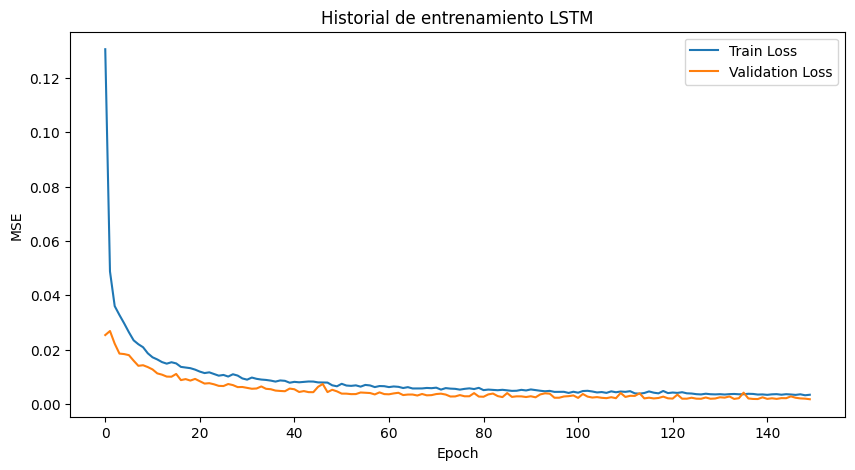

In [4]:
# 3. Entrenamiento con EarlyStopping
# El EarlyStopping detendrá el entrenamiento si la val_loss no mejora en 15 épocas
# y restaurará los mejores pesos encontrados, no los de la última época.
early_stopping = EarlyStopping(
    monitor='val_loss', 
    patience=15, 
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train, y_train, 
    epochs=150, # Ahora podemos dejar 150 porque EarlyStopping lo detendrá antes
    batch_size=32, 
    validation_split=0.1, 
    callbacks=[early_stopping], # Añadido aquí
    verbose=1
)

# Gráfico de historial
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Historial de entrenamiento LSTM")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

# 4. Evaluación

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Test MSE (Datos escalados): 0.00199 
------------------------------
Test MAPE: 0.01152 (1.15%)
Test Accuracy: 0.98848 (98.85%)
Test MSE (en puntos^2): 1290.01
Test MAE (Error medio en puntos): 29.15
------------------------------


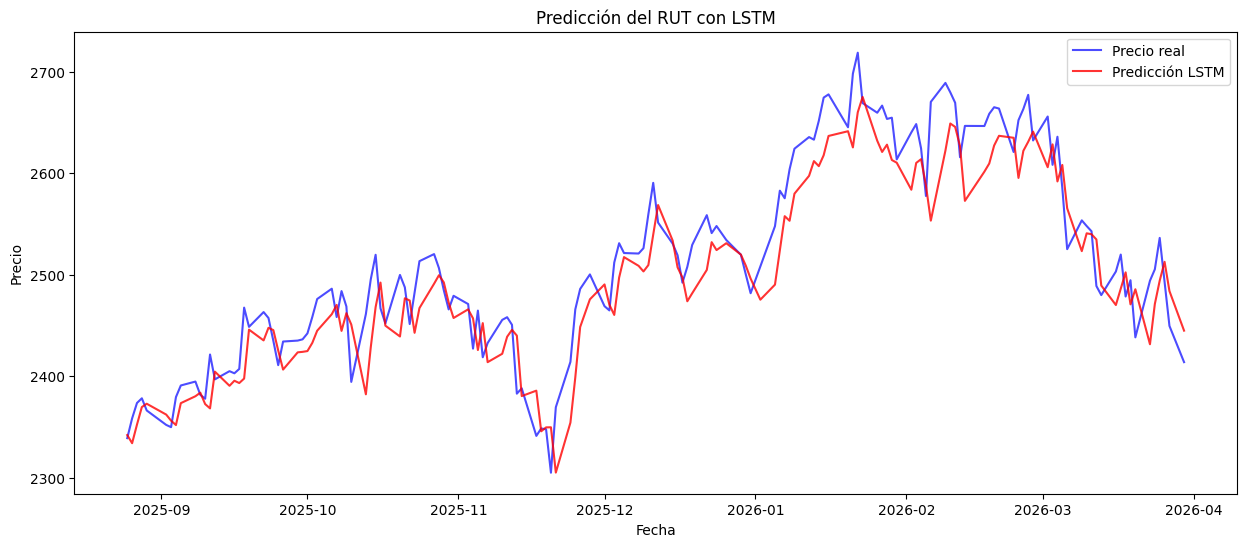

In [5]:
# 4. Evaluación
y_pred = model.predict(X_test)

# 1º. DESESCALAMOS PRIMERO (Volvemos a dólares reales)
scaler_y = MinMaxScaler()
scaler_y.fit(df['Price'].iloc[:split].values.reshape(-1, 1)) 

y_test_true = scaler_y.inverse_transform(y_test.reshape(-1, 1))
y_pred_true = scaler_y.inverse_transform(y_pred.reshape(-1, 1))

# 2º. CALCULAMOS MÉTRICAS CON LOS DATOS REALES 
mape = mean_absolute_percentage_error(y_test_true, y_pred_true)
mse_real = mean_squared_error(y_test_true, y_pred_true)
mae_real = mean_absolute_error(y_test_true, y_pred_true)
accuracy = 1 - mape

# Calculamos el MSE sobre las predicciones puras de la red (datos escalados entre 0 y 1)
mse_escalado = mean_squared_error(y_test, y_pred)

print(f"Test MSE (Datos escalados): {mse_escalado:.5f} ")

print("-" * 30)
print(f"Test MAPE: {mape:.5f} ({(mape*100):.2f}%)")
print(f"Test Accuracy: {accuracy:.5f} ({(accuracy*100):.2f}%)")
print(f"Test MSE (en puntos^2): {mse_real:.2f}")
print(f"Test MAE (Error medio en puntos): {mae_real:.2f}")
print("-" * 30)

# Fechas correspondientes a test
dates_test = df['Date'].iloc[split+time_steps:].reset_index(drop=True)

# Asegurarse de que las longitudes coincidan antes de plotear
min_len = min(len(dates_test), len(y_test_true))

# Gráfico de comparación
plt.figure(figsize=(15,6))
plt.plot(dates_test[:min_len], y_test_true[:min_len], color='blue', label='Precio real', alpha=0.7)
plt.plot(dates_test[:min_len], y_pred_true[:min_len], color='red', label='Predicción LSTM', alpha=0.8)
plt.title("Predicción del RUT con LSTM")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.show()

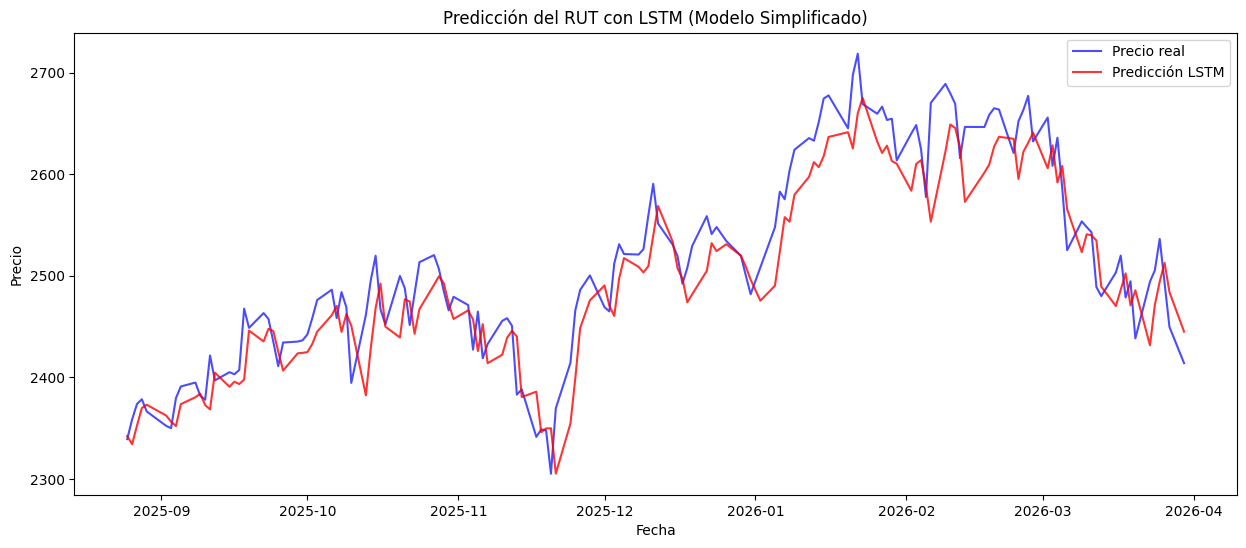

In [6]:
# CORRECCIÓN DE DATA LEAKAGE:
scaler_y = MinMaxScaler()
# Ajustamos solo hasta el índice 'split'
scaler_y.fit(df['Price'].iloc[:split].values.reshape(-1, 1)) 

y_test_true = scaler_y.inverse_transform(y_test.reshape(-1, 1))
y_pred_true = scaler_y.inverse_transform(y_pred.reshape(-1, 1))

# Fechas correspondientes a test
dates_test = df['Date'].iloc[split+time_steps:].reset_index(drop=True)

# Asegurarse de que las longitudes coincidan antes de plotear
min_len = min(len(dates_test), len(y_test_true))

# Gráfico de comparación
plt.figure(figsize=(15,6))
plt.plot(dates_test[:min_len], y_test_true[:min_len], color='blue', label='Precio real', alpha=0.7)
plt.plot(dates_test[:min_len], y_pred_true[:min_len], color='red', label='Predicción LSTM', alpha=0.8)
plt.title("Predicción del RUT con LSTM (Modelo Simplificado)")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.show()

### Revisión con valor concreto

In [8]:
fecha_busqueda = "2025-10-15"

# Convertimos a datetime
fecha_busqueda = pd.to_datetime(fecha_busqueda)

# Crear DataFrame con resultados
resultados = pd.DataFrame({
    "Fecha": dates_test[:min_len].values,
    "Valor_Real": y_test_true[:min_len].flatten(),
    "Valor_Predicho": y_pred_true[:min_len].flatten()
})

# Buscar fecha exacta
fila = resultados[resultados["Fecha"] == fecha_busqueda]

if not fila.empty:
    real = fila["Valor_Real"].values[0]
    predicho = fila["Valor_Predicho"].values[0]
    error = abs(real - predicho)

    print(f"Fecha: {fecha_busqueda.date()}")
    print(f"Valor real: {real:.2f}")
    print(f"Valor predicho: {predicho:.2f}")
else:
    print("No existe esa fecha en el conjunto de test.")
    print("Prueba con una fecha dentro del rango:")
    print(resultados["Fecha"].min().date(), "hasta", resultados["Fecha"].max().date())

Fecha: 2025-10-15
Valor real: 2519.75
Valor predicho: 2468.23
